In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [ ]:
df = pd.read_csv("../data/raw/insurance.csv")
FIGURES_PATH = Path("../reports/figures")
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

## Exploratory Data Analysis
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [ ]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
## Remove duplicates
df = df[df.duplicated() == False]
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
## Verifing null values
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
## Analyzing why the charges are so high
biggest_charger = df.loc[df["charges"].idxmax()]

print("Biggest charger:")
print(biggest_charger)

Biggest charger:
age                  54
sex              female
bmi               47.41
children              0
smoker              yes
region        southeast
charges     63770.42801
Name: 543, dtype: object


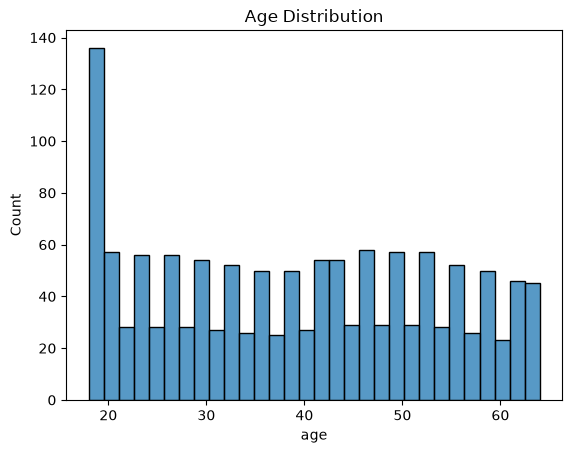

In [ ]:
## Checking histogram (Age distribution)
sns.histplot(data=df, x="age", bins=30)
plt.title("Age Distribution")
plt.show()

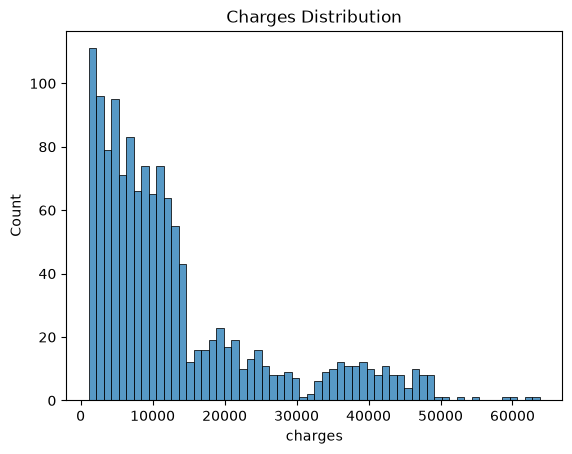

In [ ]:
## Checking histogram (Charges distribution)
sns.histplot(data=df, x="charges", bins=60)
plt.title("Charges Distribution")
plt.savefig(FIGURES_PATH / "01-charges-distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Charges distribution.** The target is right-skewed: the mean (≈13.3k) is about 40% higher than the median (≈9.4k), pulled up by a long tail of high costs. The histogram also shows three groups that persist across different bin sizes: most people below ~15k, a second group between ~15k and ~30k, and a third one between ~33k and ~50k.


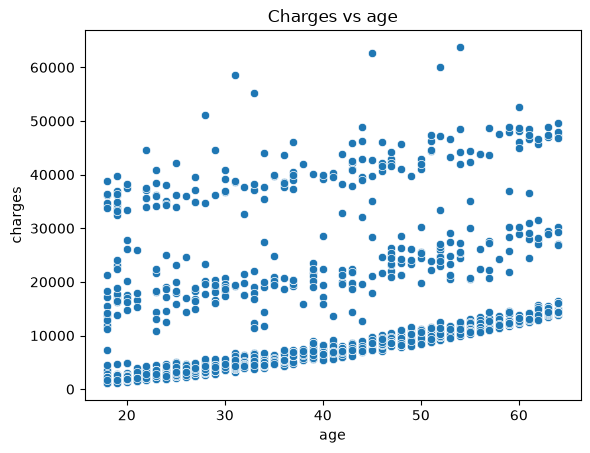

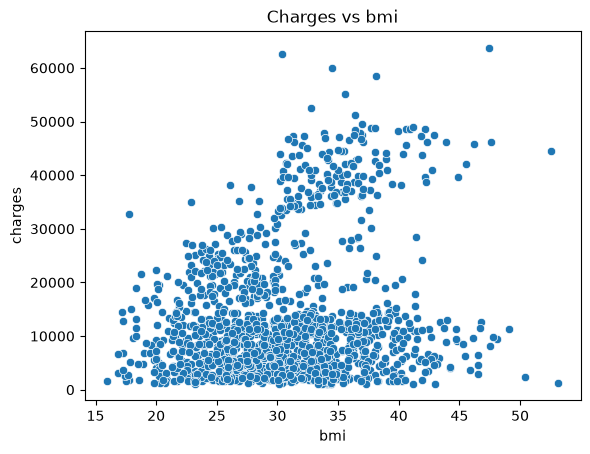

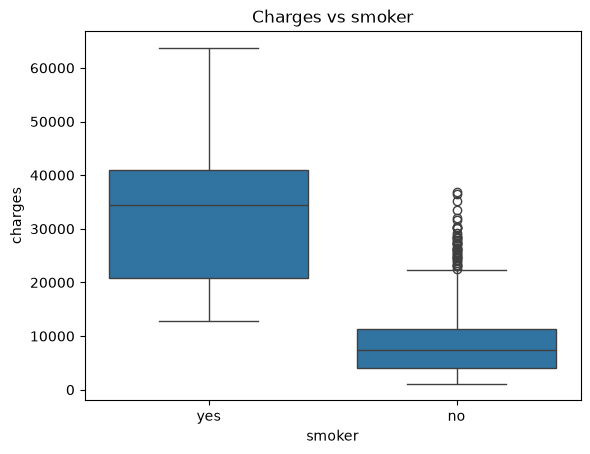

In [ ]:
## Checking wich one separates the charges the most
numeric_data = ["age", "bmi"]
text_data = "smoker"

for i, data in enumerate(numeric_data, start=2):
    sns.scatterplot(data=df, x=data, y="charges")
    plt.title(f"Charges vs {data}")
    plt.savefig(
        FIGURES_PATH / f"{i:02d}-charges-vs-{data}.png", dpi=150, bbox_inches="tight"
    )
    plt.show()

sns.boxplot(data=df, x=text_data, y="charges")
plt.title(f"Charges vs {text_data}")
plt.show()

**Charges vs. age, BMI and smoker.** Age has a clear positive relationship with charges: costs rise with age, forming three parallel bands. BMI alone shows no clear pattern: there are two clouds of points that BMI by itself does not explain. 
Smoking separates charges the most: the median for smokers (≈34k) is almost 5× the median for non-smokers (≈7k).

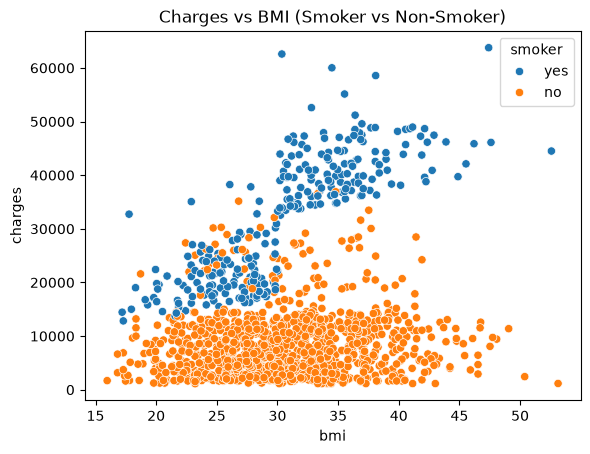

In [ ]:
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker")
plt.title("Charges vs BMI (Smoker vs Non-Smoker)")
plt.savefig(
    FIGURES_PATH / "04-charges-vs-bmi-by-smoker.png", dpi=150, bbox_inches="tight"
)
plt.show()

**Smoker × BMI interaction.** Coloring by smoker explains the two clouds. For non-smokers, charges barely change as BMI increases. For smokers, crossing BMI ≈ 30 makes charges jump above ~30k.
In other words, the effect of BMI depends on whether the person smokes: an interaction between
the two features.


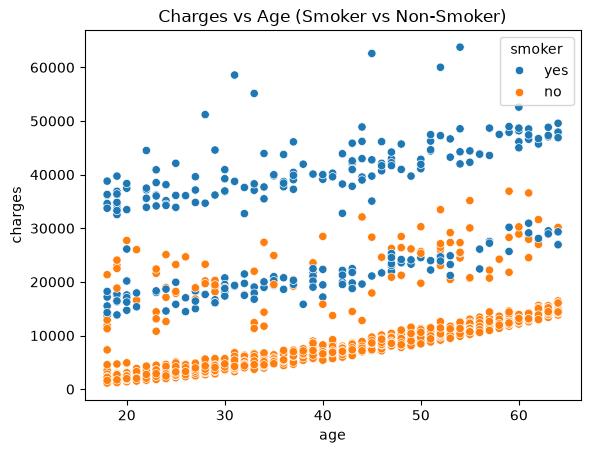

In [ ]:
## Checking correlation between the datas
sns.scatterplot(data=df, x="age", y="charges", hue="smoker")
plt.title("Charges vs Age (Smoker vs Non-Smoker)")
plt.savefig(
    FIGURES_PATH / "05-charges-vs-age-by-smoker.png", dpi=150, bbox_inches="tight"
)
plt.show()

**Charges vs. age by smoker.** The three bands are: non-smokers (bottom), mostly smokers with
BMI < 30 (middle) and smokers with BMI ≥ 30 (top). Age raises charges by roughly the same amount in all three groups (parallel bands), so its effect does not depend on other features. This is the kind of relationship a linear model can capture well.


## Conclusions

**Data quality**
- 1,338 rows × 7 columns, no missing values.
- 1 duplicated row found. It must be removed **before** the train/test split, otherwise the same
  record could end up in both sets and inflate the test metrics (data leakage).

**Target (`charges`)**
- Right-skewed: mean (≈13.3k) well above the median (≈9.4k).
- Three groups that persist across bin sizes: below ~15k, ~15k–30k and ~33k–50k.
- The high values are real customers, not errors, so they stay in the data.

**What drives the cost**
- **Smoker** is the strongest factor: the median for smokers is almost 5× higher than for non-smokers.
- **Age** increases charges by roughly the same amount in every group (parallel bands).
- **BMI** alone shows no clear pattern, but **interacts with smoking**: it barely matters for
  non-smokers, while smokers with BMI ≥ 30 jump above ~30k.
- `sex`, `children` and `region` were not explored in depth here; their weight will be checked
  through the models.

**Implications for modeling**
- A plain **Linear Regression** gives one fixed weight per feature, so it cannot represent the
  smoker × BMI interaction. Larger errors are expected for smokers with high BMI.
- A **Random Forest** splits the data step by step (e.g. smoker? → BMI > 30?), so it should
  capture the interaction on its own.
- Creating a `smoker × bmi` feature by hand should help the Linear Regression close that gap.
